# 사전학습모델 (Pretrained Model)의 활용

### Keras Pretrained 모델 성능

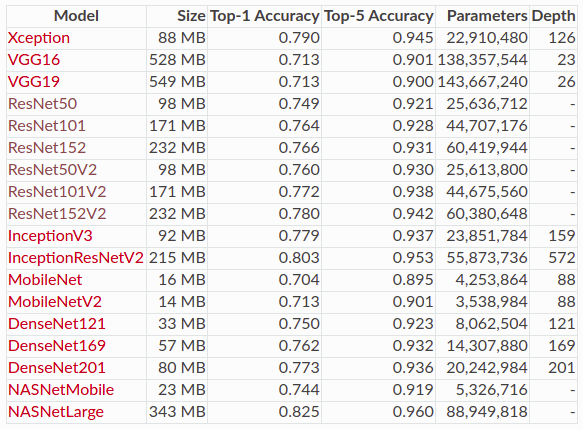

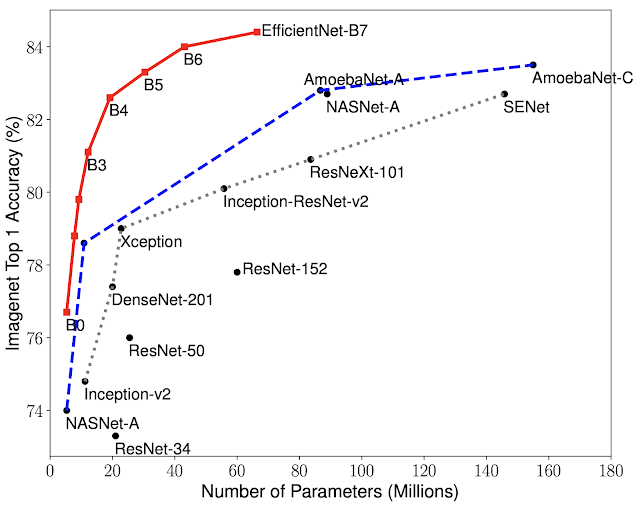

- Xception: François Chollet, 프랑소와 샤올레(케라스 프레임워크 창시자)
- Xception과 비등한 성능을 가진 모델: Inception, ResNet

## (복습) **CNN Network**의 구성<br>

### 전통적으로 **Feature Extractor(특성추출)과 Classification Layer(분류기)** <br> 두 단계로 이루어져 왔습니다.

### **Feature Extractor** 
특성 추출은 원본 pixel에서 카테고리를 분류할 수 있는 상위수준 정보를 추출하는 과정입니다. <br>
전통적인 특성 추출 기법으로는 GIST, HOG, SIFT, LBP 등이 있습니다. <br>
추출된 특징을 사용하여 SVM, Logistic Regression, Random Forest등의 분류 모델을 학습합니다. <br>

하지만 이 방식들의 문제점은, <br>
선택한 특징이 카테고리 구분에 부적합하다면 어떤 분류 전략을 사용해도 정확도가 크게 떨어지는 단점이 있으므로, <br>
도메인에 맞춰 수동으로 많은 파라미터를 튜닝해야 하는 어려움이 있습니다. <br>

반면, CNN은 **특징추출**과 **분류**를 **통합**하여 지도학습을 통해 **스스로 최적의 특성을 학습**합니다. 이는 인간이 사물을 인식하는 방식과 유사합니다.<br>
<br>
<br>

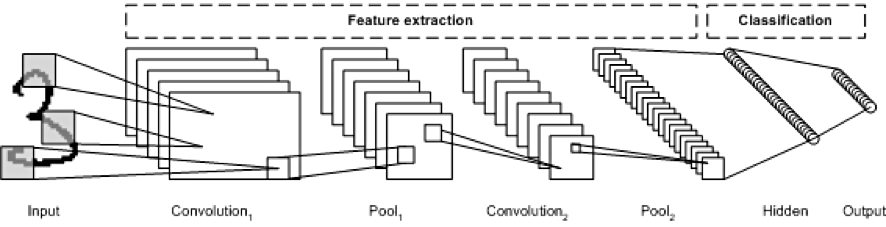
<br> 이미지; CNN 모델의 구조




<br>
CNN 모델을 설계할 때 또한 고려해야할 주요 사항으로는, 정확도와 계산 효율성이 있습니다.
<br>



### 정확도(Accuracy) <br>
분류 시스템의 성능을 평가할 때 정확도는 매우 중요합니다. <br>
정확도는 모델 뿐만 아니라 학습 데이터의 양에 의해 결정되므로, <br>
대부분의 모델은 ImageNet과 같은 큰 규모의 표준 데이터셋에서 평가됩니다. <br>
VGG 학습에 활용된 ImageNet 데이터셋에는 1,000개 카테고리에 속한 120만 장의 이미지가 포함되어 있습니다.


### 계산 효율성(Efficiency) <br> 
이미지 데이터의 특성 상 대부분의 CNN은 훈련 시 엄청난 메모리와 연산이 필요합니다. <br>
또한 모바일 기기에 모델을 배포할 경우 모델 크기도 상당히 중요한 고려사항입니다. <br>
 일반적으로 정확도를 높이기 위해서는 더 많은 계산 비용이 든다는 트레이드오프가 있습니다.




- 출처: 모두의 연구소, 
https://modulabs.co.kr/blog/vggnet_structure

## VGG 16의 구조 및 구현 세부사항

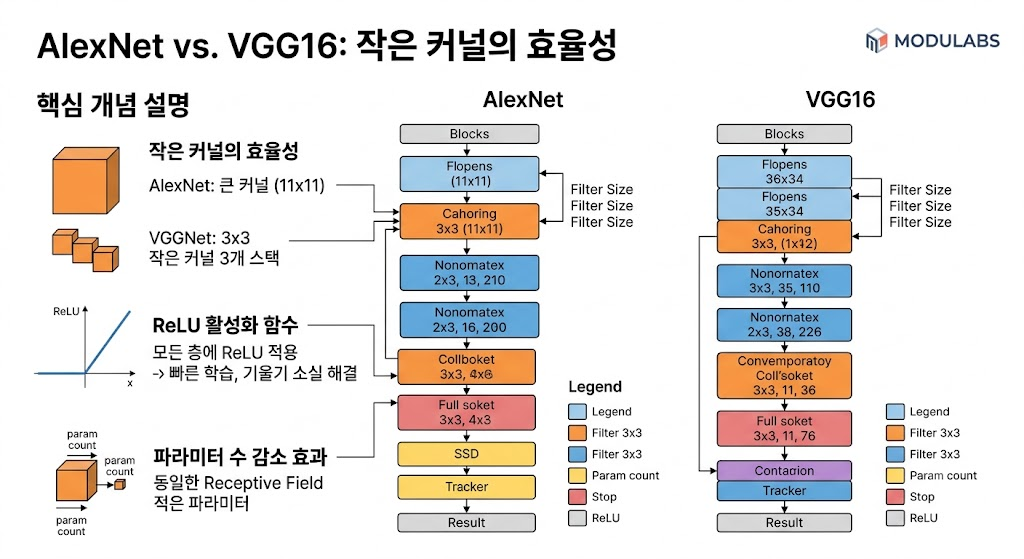

VGG 모델은 **네트워크의 깊이와 모델성능**의 영향에 집중하였다. <br>
kernel_size를 Alexnet과 다르게 (3x3)으로 고정하였는데, <br>
그 이유는 커널 사이즈가 크면 image_size 축소가 급격하게 이루어져서 <br>
깊은 층을 만들기 어렵고, 방대한 파라미터 수와 연산량을 필요로 하기 때문이다.
<br>
<br>

***Alexnet에서도 그랬던 것 처럼, 네트워크의 깊이에 따라 모델의 성능이 더 좋아진 것을 알 수 있다***

- kernel_size = (3x3) * 2개 적용한 경우 = 18개 <br>
- kernel_size = (5x5) * 1개 적용한 경우 = 25개 <br>
    -> 그림을 보면, (3x3) kernel을 2번 적용하므로써 2번 추상화 시킬수 있고, 최종으로 5x5의 추상화도 시킬수 있다. <br>
    ( 또한 파라미터의 수도 더 적음 )

<br>

#### 넓은 크기의 커널로 컨볼루션 연산을 적용하는 것보다,
#### 여러 개의 3x3 size의 kernel로 컨볼루션 연산을 수행하는 것이 더 뛰어난 feature를 추출할 수 있음

<br>



## VGG 16 - (AlexNet 대비) 두 가지 주요 개선 사항  <br>

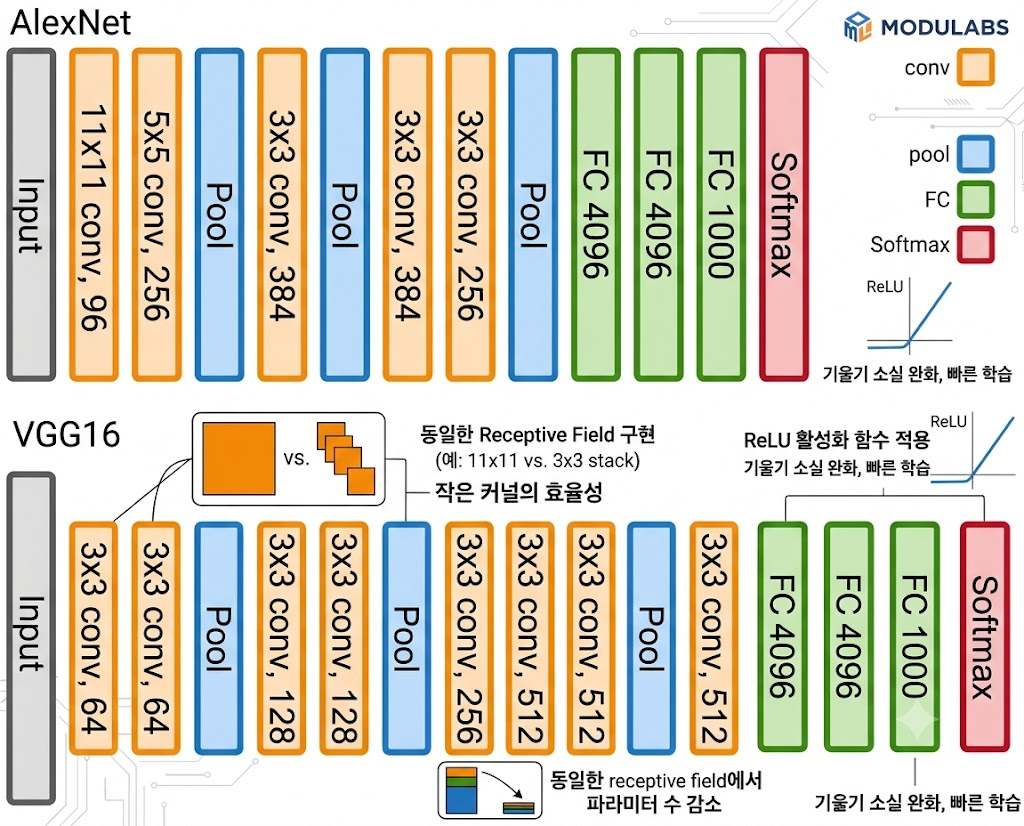

1. 큰 커널(11x11, 5x5) 대신 3x3 크기의 작은 커널을 여러 개 쌓아 사용했습니다. <br>
이렇게 하면 동일한 receptive field에서 파라미터 수를 크게 줄일 수 있습니다. 


2. 모든 conv층과 FC층 뒤에 ReLU 활성화 함수를 적용했습니다. <br>
ReLU는 sigmoid 함수에 비해 기울기 소실 문제가 적어 빠른 학습이 가능합니다.





출처<br>
(티스토리)LCY 님의 블로그<br>
https://lcyking.tistory.com/entry/VGG-%EB%AA%A8%EB%8D%B8%EC%9D%98-%EA%B0%9C%EC%9A%94-%EB%B0%8F-%ED%8A%B9%EC%A7%95 <br>

#### 성능 및 결과<br>

VGG-16은 ILSVRC 2012와 2013 대회에서 단일 모델 기준 최고 수준의 성능(7.0% 테스트 오차율)을 보여주었습니다.<br> 이는 우승작인 GoogLeNet(6.7%)에 근접한 수치입니다. <br>

VGG 그룹은 깊이를 늘리면 정확도가 향상되며, 적절한 규제를 통해 과적합을 방지할 수 있다는 점을 적절하게 보여주었습니다. <br>
하지만 한계점 역시 명확했습니다. 모델의 깊이가 어느 정도 수준을 넘어서면서 규제 기법만으로 과적합을 피할 수 없게 되었습니다.

#### 함께 비교해보면 좋은 모델들
### GoogLeNet(Inception) <br>
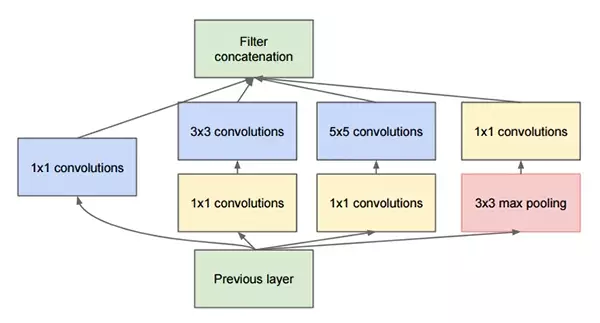 <br>
: VGG의 계산 효율성을 개선하고자 고안되었습니다.<br>
양한 커널 크기와 병목 구조(bottleneck)를 적극 활용한 Inception 모듈을 통해 파라미터 수를 절감할 수 있었습니다. <br>
마지막 FC층도 Global Average Pooling으로 대체하여 모델 크기를 대폭 줄였습니다. <br>
이를 통해 VGG 대비 뛰어난 계산 효율성과 93.3%의 높은 정확도를 달성했습니다.<br>

### Residual Network(ResNet) <br>
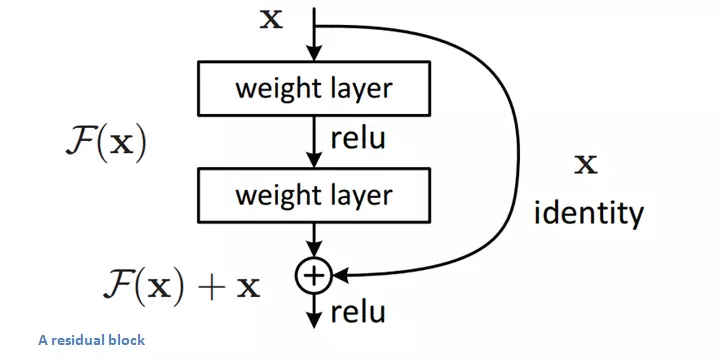 <br>
잔차 연결(residual connection)을 활용한 블록 구조를 통해 극심한 기울기 소실과 degradation 문제를 효과적으로 해결했습니다. <br>
이를 통해 최대 152층의 훨씬 깊은 네트워크를 구축할 수 있었습니다. <br>
152층 ResNet은 95.51%의 최고 정확도를 기록하며 VGG와 GoogLeNet을 뛰어넘었습니다.

# Transfer Learning(전이학습)

- 기존에 학습된 모델, feature extractor 계열에 있던 cnn weight를 모두 가져와서 사용.

- 만약 새로운 데이터가 들어오면, 이때부터 weight 초기화가 이루어짐 <br>
-> weight 초기화가 시작되면 자신이 가지고있는 모델을 가지고 학습함

- tf.keras의 사전학습 모델은 대부분 ImageNet 데이터 셋으로 사전 훈련된 모델들이다.

- pretrained 모델의 **feature extractor 기반**으로 **재학습**을 시키는 것으로 활용 <br>
물론, feature extractor를 학습 안하는것은 아니며, 학습된 파라미터?를 가져와서 **필요에 맞게 수정**하는 느낌 <br>
(아예 처음부터 weight, initialization, glory unit, uniform 부터 하지않는다는 뜻)